# CSE428 — Pet Image Segmentation & Classification
### Oxford-IIIT Pet Dataset — U-Net & Attention U-Net with joint classification head

## 0. Setup

In [1]:
#Loading dependencies
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.datasets import OxfordIIITPet

In [2]:
#Loading dataset with labels and masks
dataset_trainval = OxfordIIITPet(
    root="/kaggle/working/oxford_pet",
    split="trainval",
    target_types=["category", "segmentation"],
    download=True
)

dataset_test = OxfordIIITPet(
    root="/kaggle/working/oxford_pet",
    split="test",
    target_types=["category", "segmentation"],
    download=True
)

class_names = dataset_trainval.classes
num_classes = len(class_names)
print(num_classes)

37


In [3]:
#Sanity check
print(len(dataset_trainval), len(dataset_test), num_classes)

3680 3669 37


In [4]:
#Setting compute device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [5]:
#Checkpoint utilities
CHECKPOINT_DIR = "/kaggle/working/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

def save_checkpoint(model_dict, optimizer, epoch, best_metric, checkpoint_name, scheduler=None):
    checkpoint = {'epoch': epoch, 'best_metric': best_metric, 'optimizer_state_dict': optimizer.state_dict()}
    if scheduler is not None:
        checkpoint['scheduler_state_dict'] = scheduler.state_dict()
    for name, model in model_dict.items():
        checkpoint[f'{name}_state_dict'] = model.state_dict()
    torch.save(checkpoint, f"{CHECKPOINT_DIR}/{checkpoint_name}.pt")

def load_checkpoint(model_dict, optimizer, checkpoint_name, scheduler=None):
    path = f"{CHECKPOINT_DIR}/{checkpoint_name}.pt"
    if not os.path.exists(path):
        return 0, None
    checkpoint = torch.load(path, map_location=device)
    try:
        for name, model in model_dict.items():
            model.load_state_dict(checkpoint[f'{name}_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        if scheduler is not None and 'scheduler_state_dict' in checkpoint:
            scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
        return checkpoint['epoch'], checkpoint['best_metric']
    except (RuntimeError, KeyError) as e:
        print(f"Warning: checkpoint '{checkpoint_name}' is incompatible with the current model architecture and will be ignored ({e}).")
        return 0, None

## 1. Data Exploration

In [6]:
#Merging boundary pixels into foreground
def trimap_to_binary(trimap_arr):
    return ((trimap_arr == 1) | (trimap_arr == 3)).astype(np.uint8)

In [7]:
#Building image, mask, and label arrays
from PIL import Image

IMG_SIZE = 128

def load_split(dataset):
    images, masks, labels = [], [], []
    for img, (label, trimap) in dataset:
        img = img.convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        trimap = trimap.resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)
        images.append(np.array(img))
        masks.append(trimap_to_binary(np.array(trimap)))
        labels.append(label)
    return np.array(images), np.array(masks), np.array(labels)

x_trainval, y_mask_trainval, y_trainval = load_split(dataset_trainval)
x_test, y_mask_test, y_test = load_split(dataset_test)

In [8]:
#Splitting trainval into train and validation sets
from sklearn.model_selection import train_test_split

train_idx, val_idx = train_test_split(
    np.arange(len(y_trainval)),
    test_size=0.15,
    stratify=y_trainval,
    random_state=125
)

x_train, y_mask_train, y_train = x_trainval[train_idx], y_mask_trainval[train_idx], y_trainval[train_idx]
x_val, y_mask_val, y_val = x_trainval[val_idx], y_mask_trainval[val_idx], y_trainval[val_idx]

print(len(x_train), len(x_val), len(x_test))

3128 552 3669


In [9]:
#Normalizing pixel values
x_train_f = x_train.astype(np.float32) / 255.0
x_val_f = x_val.astype(np.float32) / 255.0
x_test_f = x_test.astype(np.float32) / 255.0

mean = x_train_f.mean(axis=(0,1,2), keepdims=True)
std = x_train_f.std(axis=(0,1,2), keepdims=True)

x_train_norm = (x_train_f - mean) / (std + 1e-4)
x_val_norm = (x_val_f - mean) / (std + 1e-4)
x_test_norm = (x_test_f - mean) / (std + 1e-4)

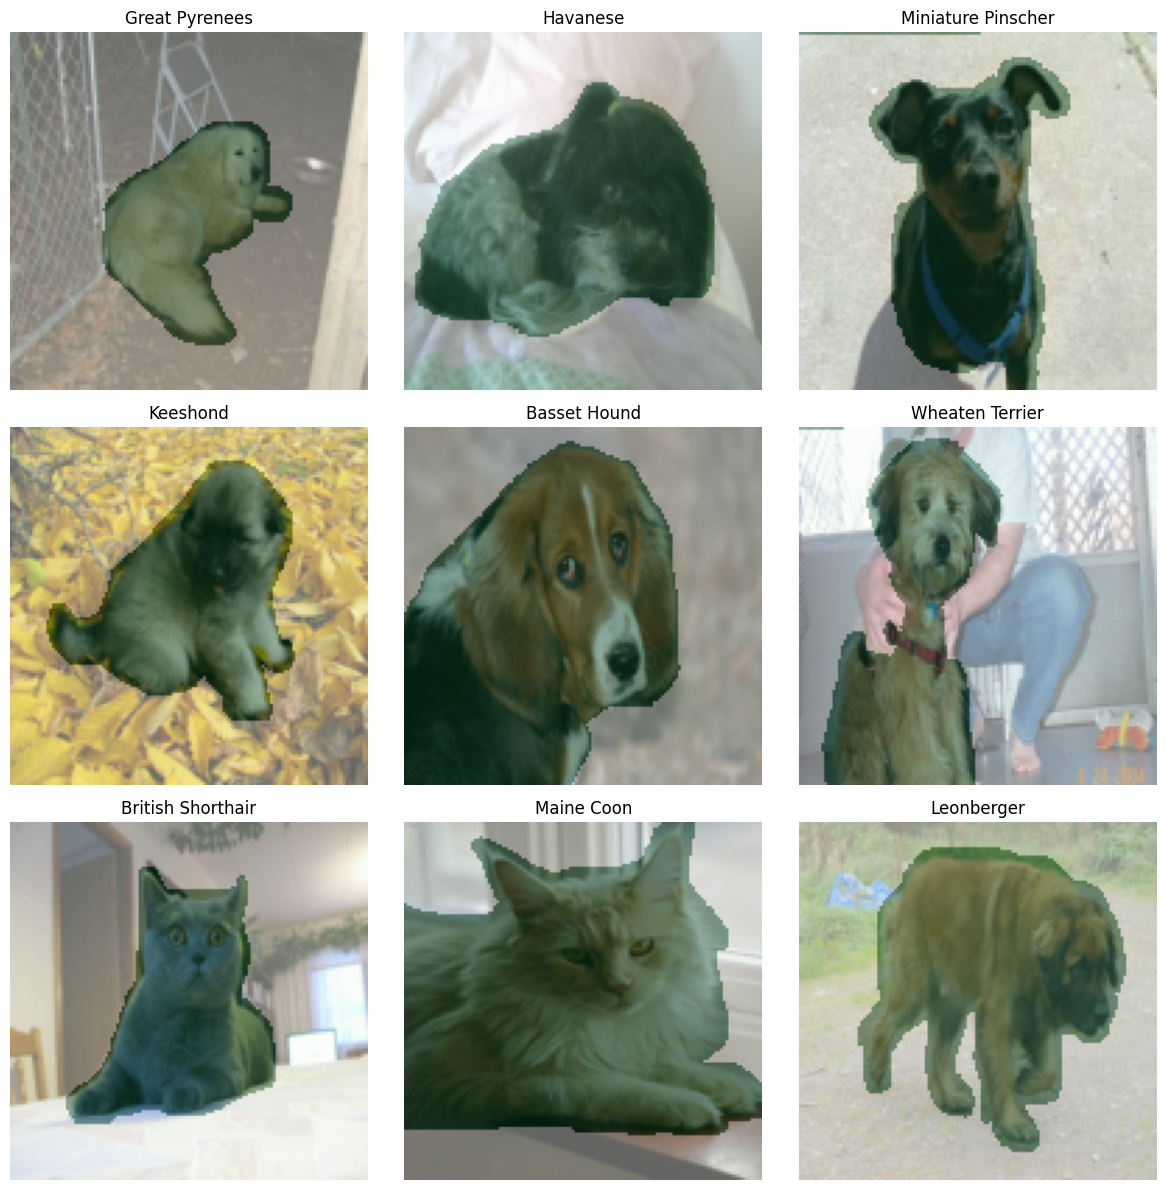

In [10]:
#Visualizing random samples with mask overlays
def show_grid(images, masks, labels, class_names, n=9, seed=None):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(images), size=n, replace=False)
    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    for ax, i in zip(axes.flat, idx):
        ax.imshow(images[i])
        ax.imshow(masks[i], cmap='Greens', alpha=0.4)
        ax.set_title(class_names[labels[i]])
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_grid(x_train, y_mask_train, y_train, class_names)

In [11]:
#Batch loader for training
class BatchLoader():
    def __init__(self, x, y_label, y_mask, shuffle=True, batch_size=16, device='cpu'):
        self.x = torch.tensor(x, dtype=torch.float32).permute(0, 3, 1, 2)
        self.y_label = torch.tensor(y_label, dtype=torch.long)
        self.y_mask = torch.tensor(y_mask, dtype=torch.float32)
        self.shuffle = shuffle
        self.batch_size = batch_size
        self.device = device
        self.n = len(x)
        self.len = (self.n + batch_size - 1) // batch_size
        self.iter = 0
        self.order = np.arange(self.n)
        if self.shuffle:
            np.random.shuffle(self.order)

    def next(self, task='both'):
        start = self.iter * self.batch_size
        end = min(start + self.batch_size, self.n)
        batch_idx = self.order[start:end]

        self.iter += 1
        if self.iter >= self.len:
            self.iter = 0
            if self.shuffle:
                np.random.shuffle(self.order)

        x_batch = self.x[batch_idx].to(self.device)
        if task == 'classification':
            return x_batch, self.y_label[batch_idx].to(self.device)
        elif task == 'segmentation':
            return x_batch, self.y_mask[batch_idx].to(self.device)
        else:
            return x_batch, self.y_label[batch_idx].to(self.device), self.y_mask[batch_idx].to(self.device)

In [12]:
#Instantiating loaders
train_loader = BatchLoader(x_train_norm, y_train, y_mask_train, batch_size=16, device=device)
val_loader = BatchLoader(x_val_norm, y_val, y_mask_val, shuffle=False, batch_size=16, device=device)

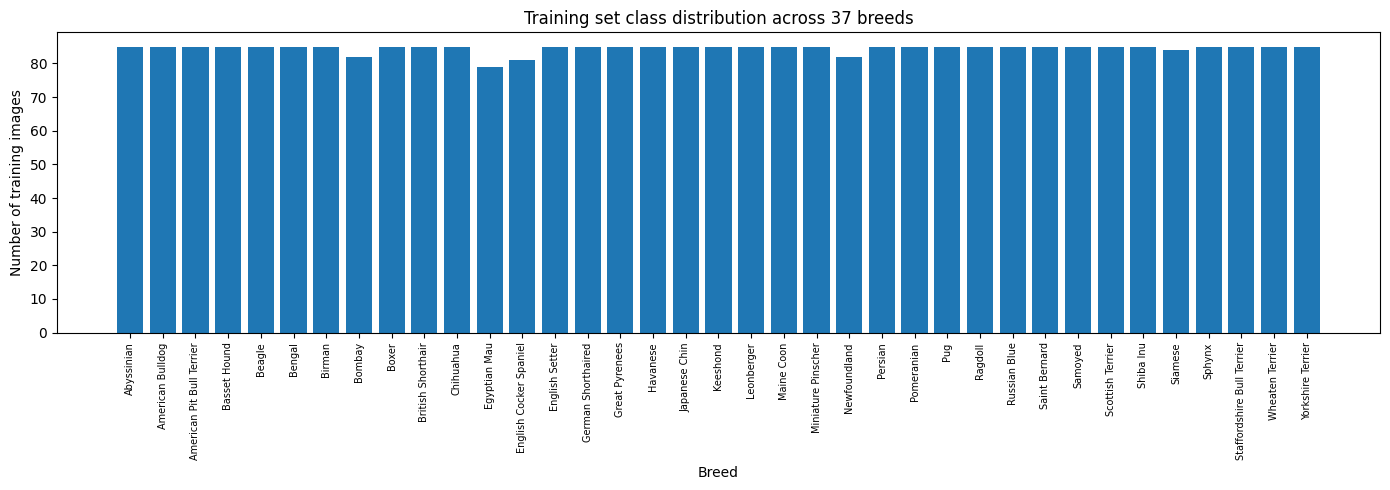

In [13]:
#Breed class distribution
counts = np.bincount(y_train, minlength=num_classes)
fig, ax = plt.subplots(figsize=(14,5))
ax.bar(range(num_classes), counts)
ax.set_xticks(range(num_classes))
ax.set_xticklabels(class_names, rotation=90, fontsize=7)
ax.set_xlabel('Breed')
ax.set_ylabel('Number of training images')
ax.set_title('Training set class distribution across 37 breeds')
plt.tight_layout()
plt.show()

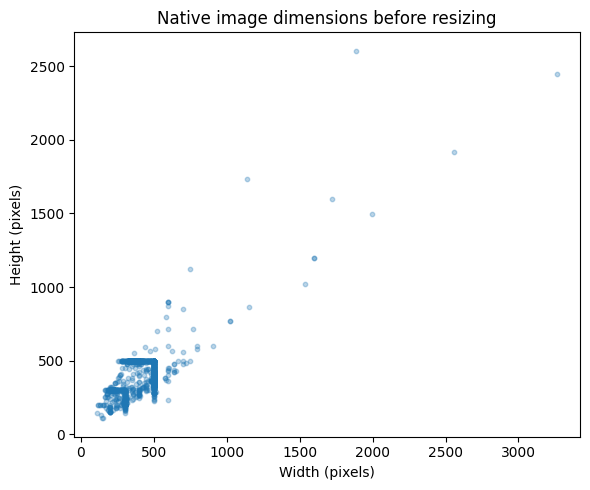

In [14]:
#Native image size distribution before resizing
widths, heights = [], []
for img, _ in dataset_trainval:
    w, h = img.size
    widths.append(w)
    heights.append(h)

fig, ax = plt.subplots(figsize=(6,5))
ax.scatter(widths, heights, alpha=0.3, s=10)
ax.set_xlabel('Width (pixels)')
ax.set_ylabel('Height (pixels)')
ax.set_title('Native image dimensions before resizing')
plt.tight_layout()
plt.show()

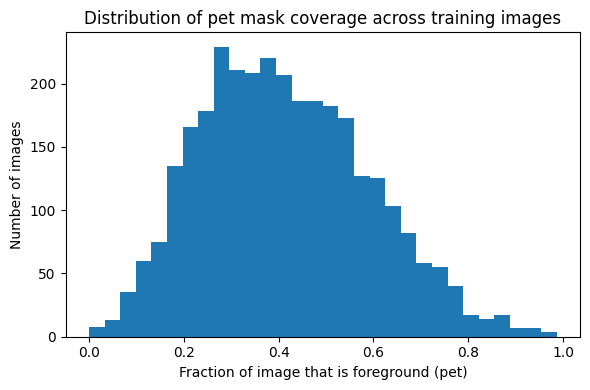

In [15]:
#Mask coverage per image
coverage = y_mask_train.reshape(len(y_mask_train), -1).mean(axis=1)
fig, ax = plt.subplots(figsize=(6,4))
ax.hist(coverage, bins=30)
ax.set_xlabel('Fraction of image that is foreground (pet)')
ax.set_ylabel('Number of images')
ax.set_title('Distribution of pet mask coverage across training images')
plt.tight_layout()
plt.show()

**Observations:** Breed classes are reasonably balanced across the training set, which is why no class-weighting was applied during classifier training. Native image dimensions vary substantially across the dataset, motivating the fixed 128×128 resize applied during preprocessing. Pet masks typically cover a large majority of each frame, which helps explain why even a shallow U-Net reaches a strong segmentation IoU relatively quickly — the foreground is rarely small or hard to locate.

## 2. Base U-Net + Classifier

In [16]:
#ConvBlock
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)

In [17]:
#U-Net encoder
class UNetEncoder(nn.Module):
    def __init__(self, in_channels=3, base_channels=32):
        super().__init__()
        self.enc1 = ConvBlock(in_channels, base_channels)
        self.enc2 = ConvBlock(base_channels, base_channels*2)
        self.enc3 = ConvBlock(base_channels*2, base_channels*4)
        self.enc4 = ConvBlock(base_channels*4, base_channels*8)
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        x1 = self.enc1(x)
        x2 = self.enc2(self.pool(x1))
        x3 = self.enc3(self.pool(x2))
        x4 = self.enc4(self.pool(x3))
        return x1, x2, x3, x4

In [18]:
#U-Net bottleneck
class UNetBottleneck(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.block = ConvBlock(in_channels, in_channels*2)
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        return self.block(self.pool(x))

In [19]:
#Decoder block
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.conv = ConvBlock(out_channels*2, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([skip, x], dim=1)
        return self.conv(x)

In [20]:
#U-Net decoder
class UNetDecoder(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.dec4 = DecoderBlock(in_channels, in_channels//2)
        self.dec3 = DecoderBlock(in_channels//2, in_channels//4)
        self.dec2 = DecoderBlock(in_channels//4, in_channels//8)
        self.dec1 = DecoderBlock(in_channels//8, in_channels//16)
        self.final_conv = nn.Conv2d(in_channels//16, 1, kernel_size=1)

    def forward(self, x5, x4, x3, x2, x1):
        x = self.dec4(x5, x4)
        x = self.dec3(x, x3)
        x = self.dec2(x, x2)
        x = self.dec1(x, x1)
        return self.final_conv(x).squeeze(1)

In [21]:
#Classifier head
class Classifier(nn.Module):
    def __init__(self, in_channels, num_classes):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, in_channels, 3, padding=1)
        self.conv2 = nn.Conv2d(in_channels, in_channels//2, 3, padding=1)
        self.fc = nn.Linear(in_channels//2, num_classes)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)
        x = F.relu(self.conv2(x))
        x = F.adaptive_avg_pool2d(x, (1,1)).flatten(1)
        return self.fc(x)

In [22]:
#Loss functions
class DiceLoss(nn.Module):
    def __init__(self, epsilon=1.):
        super().__init__()
        self.epsilon = epsilon

    def forward(self, preds, targets):
        preds = torch.sigmoid(preds)
        intersection = (preds * targets).sum()
        return 1 - (2. * intersection + self.epsilon) / (preds.sum() + targets.sum() + self.epsilon)

In [23]:
#Segmentation and classification metrics
def calculate_iou(preds, targets, threshold=0.5, eps=1e-6):
    preds = torch.sigmoid(preds)
    preds = (preds > threshold).float()
    intersection = (preds * targets).sum(dim=(1,2))
    union = preds.sum(dim=(1,2)) + targets.sum(dim=(1,2)) - intersection
    return ((intersection + eps) / (union + eps)).mean()

def calculate_dice(preds, targets, threshold=0.5, eps=1e-6):
    preds = torch.sigmoid(preds)
    preds = (preds > threshold).float()
    intersection = (preds * targets).sum(dim=(1,2))
    return ((2*intersection + eps) / (preds.sum(dim=(1,2)) + targets.sum(dim=(1,2)) + eps)).mean()

def calculate_pixel_accuracy(preds, targets, threshold=0.5):
    preds = torch.sigmoid(preds)
    preds = (preds > threshold).float()
    return (preds == targets).float().mean()

In [24]:
#Instantiating models and optimizer
encoder = UNetEncoder(in_channels=3, base_channels=32).to(device)
bottleneck = UNetBottleneck(256).to(device)
decoder = UNetDecoder(512).to(device)
classifier = Classifier(512, num_classes).to(device)

model_dict = {'encoder': encoder, 'bottleneck': bottleneck, 'decoder': decoder, 'classifier': classifier}

optimizer = torch.optim.AdamW(
    list(encoder.parameters()) + list(bottleneck.parameters()) +
    list(decoder.parameters()) + list(classifier.parameters()),
    lr=1e-3
)

bce_loss = nn.BCEWithLogitsLoss()
dice_loss = DiceLoss()
classifier_loss_fn = nn.CrossEntropyLoss()

In [25]:
#Generic epoch runner
def run_epoch(loader, model_dict, optimizer, train=True):
    encoder, bottleneck, decoder, classifier = model_dict['encoder'], model_dict['bottleneck'], model_dict['decoder'], model_dict['classifier']
    encoder.train(train); bottleneck.train(train); decoder.train(train); classifier.train(train)
    total_loss, total_iou, total_dice, total_acc, total_cls_acc = 0, 0, 0, 0, 0
    for _ in range(loader.len):
        x, y_label, y_mask = loader.next('both')
        with torch.set_grad_enabled(train):
            x1, x2, x3, x4 = encoder(x)
            x5 = bottleneck(x4)
            mask_pred = decoder(x5, x4, x3, x2, x1)
            label_pred = classifier(x5)

            bce = bce_loss(mask_pred, y_mask)
            dice = dice_loss(mask_pred, y_mask)
            cls_loss = classifier_loss_fn(label_pred, y_label)
            loss = (0.2*bce + 0.8*dice) + 0.5*cls_loss

        if train:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        total_loss += loss.item()
        total_iou += calculate_iou(mask_pred, y_mask).item()
        total_dice += calculate_dice(mask_pred, y_mask).item()
        total_acc += calculate_pixel_accuracy(mask_pred, y_mask).item()
        total_cls_acc += (label_pred.argmax(1) == y_label).float().mean().item()

    n = loader.len
    return total_loss/n, total_iou/n, total_dice/n, total_acc/n, total_cls_acc/n

In [26]:
#Training Base U-Net
CHECKPOINT_NAME = "base_unet"
NUM_EPOCHS = 25
SAVE_EVERY = 5

start_epoch, best_metric = load_checkpoint(model_dict, optimizer, CHECKPOINT_NAME)
best_metric = best_metric if best_metric is not None else 0

for epoch in range(start_epoch, NUM_EPOCHS):
    train_loss, train_iou, train_dice, train_acc, train_cls_acc = run_epoch(train_loader, model_dict, optimizer, train=True)
    val_loss, val_iou, val_dice, val_acc, val_cls_acc = run_epoch(val_loader, model_dict, optimizer, train=False)

    print(epoch, train_loss, train_iou, train_cls_acc, val_loss, val_iou, val_cls_acc)

    if val_iou > best_metric:
        best_metric = val_iou
        save_checkpoint(model_dict, optimizer, epoch+1, best_metric, CHECKPOINT_NAME + "_best")

    if (epoch+1) % SAVE_EVERY == 0 or (epoch+1) == NUM_EPOCHS:
        save_checkpoint(model_dict, optimizer, epoch+1, best_metric, CHECKPOINT_NAME)

In [27]:
#Training history - Base U-Net
base_unet_history = {
    'epoch': list(range(25)),
    'train_loss': [2.0553,2.0217,1.9711,1.9417,1.9037,1.8466,1.7789,1.7054,1.6346,1.5758,1.5235,1.4479,1.3992,1.3251,1.2689,1.2364,1.1439,1.0992,1.0523,0.9865,0.9366,0.8769,0.7965,0.7548,0.7278],
    'train_iou':  [0.6839,0.7104,0.7259,0.7312,0.7410,0.7507,0.7569,0.7649,0.7709,0.7741,0.7800,0.7852,0.7875,0.7927,0.7945,0.7991,0.8056,0.8075,0.8113,0.8151,0.8175,0.8192,0.8249,0.8236,0.8285],
    'train_cls_acc': [0.0392,0.0415,0.0494,0.0577,0.0689,0.0810,0.1001,0.1221,0.1521,0.1684,0.1869,0.2172,0.2325,0.2592,0.2886,0.3045,0.3520,0.3811,0.3986,0.4283,0.4608,0.5041,0.5332,0.5717,0.5826],
    'val_loss': [2.0074,1.9770,2.0959,1.9925,1.8857,1.8882,1.7777,1.7217,1.6943,1.6890,1.6426,1.7749,1.5691,1.6484,1.5313,1.5831,1.6846,1.7439,1.6461,1.7707,1.7564,1.7047,1.7872,1.6899,1.7723],
    'val_iou':  [0.7325,0.7342,0.6787,0.7261,0.7359,0.7303,0.7699,0.7755,0.7732,0.7694,0.7807,0.7856,0.7984,0.7793,0.7867,0.7873,0.7939,0.7912,0.8010,0.8026,0.8091,0.8051,0.8105,0.8104,0.8053],
    'val_cls_acc': [0.0411,0.0536,0.0571,0.0482,0.0839,0.0589,0.1143,0.1107,0.1179,0.1429,0.1518,0.1411,0.1696,0.1607,0.2089,0.1768,0.1661,0.1786,0.2196,0.1929,0.1982,0.2411,0.2250,0.2536,0.2536],
}

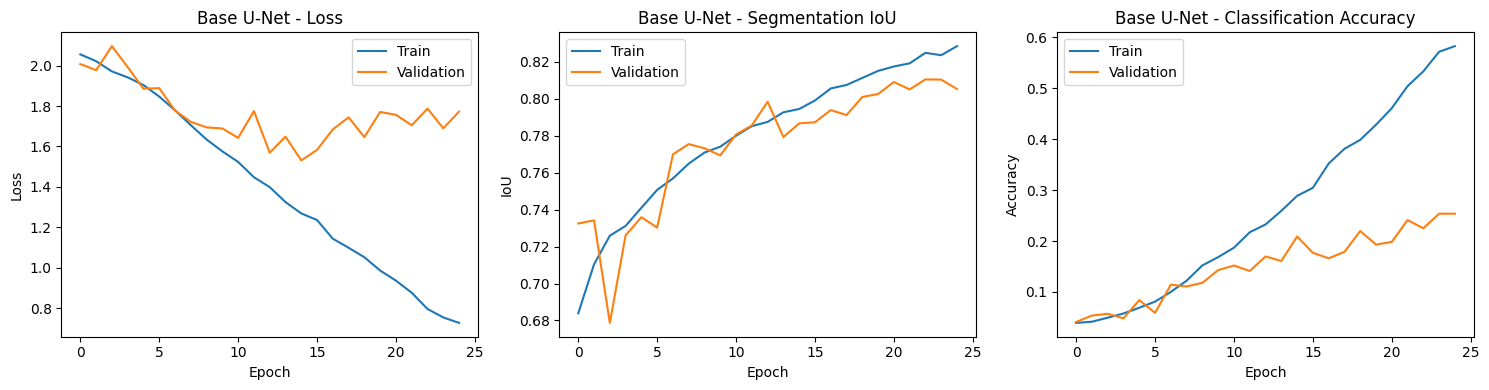

In [28]:
#Plotting training curves
def plot_history(history, title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].plot(history['epoch'], history['train_loss'], label='Train')
    axes[0].plot(history['epoch'], history['val_loss'], label='Validation')
    axes[0].set_title(f'{title} - Loss'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend()

    axes[1].plot(history['epoch'], history['train_iou'], label='Train')
    axes[1].plot(history['epoch'], history['val_iou'], label='Validation')
    axes[1].set_title(f'{title} - Segmentation IoU'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('IoU'); axes[1].legend()

    axes[2].plot(history['epoch'], history['train_cls_acc'], label='Train')
    axes[2].plot(history['epoch'], history['val_cls_acc'], label='Validation')
    axes[2].set_title(f'{title} - Classification Accuracy'); axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Accuracy'); axes[2].legend()

    plt.tight_layout()
    plt.show()

plot_history(base_unet_history, 'Base U-Net')

In [29]:
#Getting raw predictions for confusion matrix
def get_predictions(loader, model_dict):
    encoder, bottleneck, decoder, classifier = model_dict['encoder'], model_dict['bottleneck'], model_dict['decoder'], model_dict['classifier']
    encoder.eval(); bottleneck.eval(); decoder.eval(); classifier.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for _ in range(loader.len):
            x, y_label, y_mask = loader.next('both')
            x1, x2, x3, x4 = encoder(x)
            x5 = bottleneck(x4)
            label_pred = classifier(x5)
            all_preds.append(label_pred.argmax(1).cpu())
            all_labels.append(y_label.cpu())
    return torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()

In [30]:
#Plotting confusion matrix
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(preds, labels, class_names, title):
    cm = confusion_matrix(labels, preds, labels=range(len(class_names)))
    fig, ax = plt.subplots(figsize=(14, 12))
    im = ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names, rotation=90, fontsize=7)
    ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names, fontsize=7)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

In [31]:
#Instantiating test loader
test_loader = BatchLoader(x_test_norm, y_test, y_mask_test, shuffle=False, batch_size=16, device=device)

In [32]:
#Loading best checkpoint for evaluation
load_checkpoint(model_dict, optimizer, CHECKPOINT_NAME + "_best")

(23, 0.8104966827801295)

In [33]:
#Generic evaluation function
from sklearn.metrics import precision_recall_fscore_support

def evaluate(loader, model_dict):
    encoder, bottleneck, decoder, classifier = model_dict['encoder'], model_dict['bottleneck'], model_dict['decoder'], model_dict['classifier']
    encoder.eval(); bottleneck.eval(); decoder.eval(); classifier.eval()
    total_iou, total_dice, total_acc, total_cls_acc, n = 0, 0, 0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for _ in range(loader.len):
            x, y_label, y_mask = loader.next('both')
            x1, x2, x3, x4 = encoder(x)
            x5 = bottleneck(x4)
            mask_pred = decoder(x5, x4, x3, x2, x1)
            label_pred = classifier(x5)

            total_iou += calculate_iou(mask_pred, y_mask).item()
            total_dice += calculate_dice(mask_pred, y_mask).item()
            total_acc += calculate_pixel_accuracy(mask_pred, y_mask).item()
            total_cls_acc += (label_pred.argmax(1) == y_label).float().mean().item()
            all_preds.append(label_pred.argmax(1).cpu())
            all_labels.append(y_label.cpu())
            n += 1

    preds, labels = torch.cat(all_preds), torch.cat(all_labels)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='macro', zero_division=0)
    return {'mIoU': total_iou/n, 'dice': total_dice/n, 'pixel_acc': total_acc/n,
            'cls_acc': total_cls_acc/n, 'precision': precision, 'recall': recall, 'f1': f1}

In [34]:
#Reporting metrics across all splits
for name, loader in [('train', train_loader), ('val', val_loader), ('test', test_loader)]:
    r = evaluate(loader, model_dict)
    print(name, r['mIoU'], r['dice'], r['pixel_acc'], r['cls_acc'], r['precision'], r['recall'], r['f1'])

train 0.8348747884132424 0.9045103271396793 0.9288477411075514 0.5679209183673469 0.5893325556999006 0.5675684155496525 0.5495516640743139
val 0.8104966827801295 0.8874182071004595 0.9144288199288505 0.225 0.23685641116869513 0.22471042471042468 0.2089390070994698
test 0.8088054519632588 0.8863691964875097 0.9138508905535159 0.22744565217391305 0.24573108989864112 0.22763547930978556 0.2195144729085481


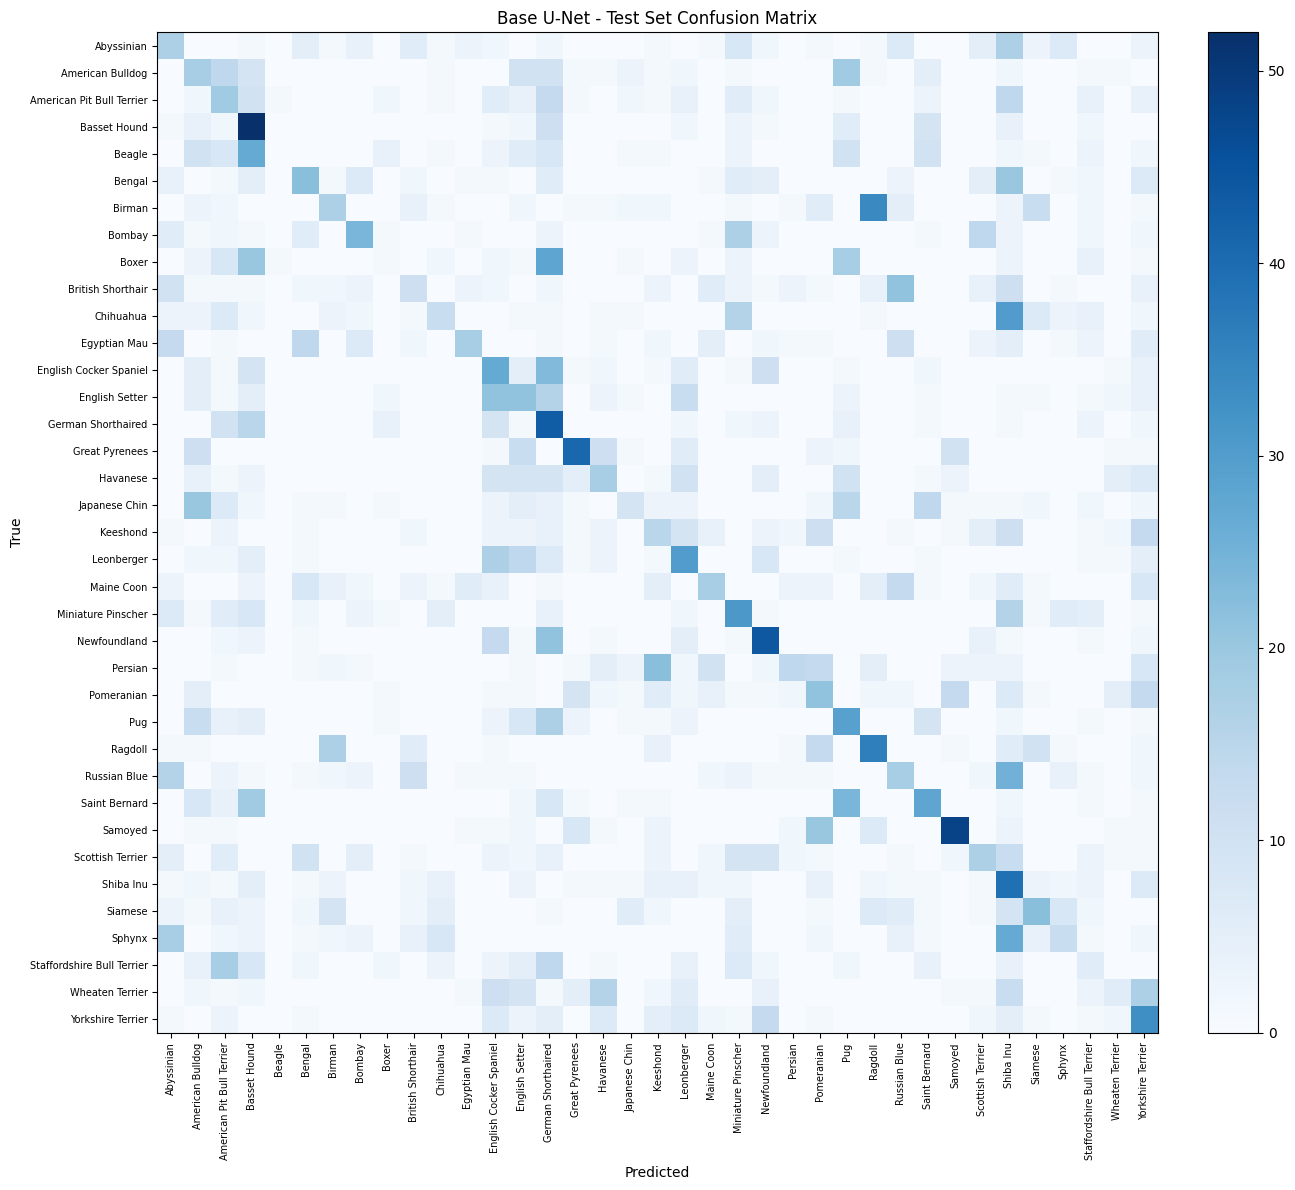

In [35]:
#Confusion matrix - Base U-Net
preds, labels = get_predictions(test_loader, model_dict)
plot_confusion_matrix(preds, labels, class_names, 'Base U-Net - Test Set Confusion Matrix')

In [36]:
#Generic inference function for single image display
def show_inference(idx, x_raw, x_norm, y_labels, y_masks, class_names, model_dict):
    encoder, bottleneck, decoder, classifier = model_dict['encoder'], model_dict['bottleneck'], model_dict['decoder'], model_dict['classifier']
    encoder.eval(); bottleneck.eval(); decoder.eval(); classifier.eval()
    x = torch.tensor(x_norm[idx:idx+1], dtype=torch.float32).permute(0,3,1,2).to(device)
    true_mask = torch.tensor(y_masks[idx], dtype=torch.float32)
    true_label = y_labels[idx]

    with torch.no_grad():
        x1, x2, x3, x4 = encoder(x)
        x5 = bottleneck(x4)
        mask_pred_logits = decoder(x5, x4, x3, x2, x1)
        label_pred = classifier(x5)

    pred_mask = (torch.sigmoid(mask_pred_logits[0]) > 0.5).float().cpu()
    pred_label = label_pred.argmax(1).item()
    iou = calculate_iou(mask_pred_logits[0:1].cpu(), true_mask.unsqueeze(0)).item()

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(x_raw[idx]); axes[0].set_title('Original image'); axes[0].axis('off')
    axes[1].imshow(x_raw[idx]); axes[1].imshow(true_mask, cmap='Greens', alpha=0.4); axes[1].set_title('Image + True mask overlay'); axes[1].axis('off')
    axes[2].imshow(x_raw[idx]); axes[2].imshow(pred_mask, cmap='Reds', alpha=0.4); axes[2].set_title('Image + Predict mask overlay'); axes[2].axis('off')

    fig.suptitle(f'Original class - "{class_names[true_label]}"\nPredicted class - "{class_names[pred_label]}"\nIoU - {iou*100:.1f}%')
    plt.tight_layout()
    plt.show()

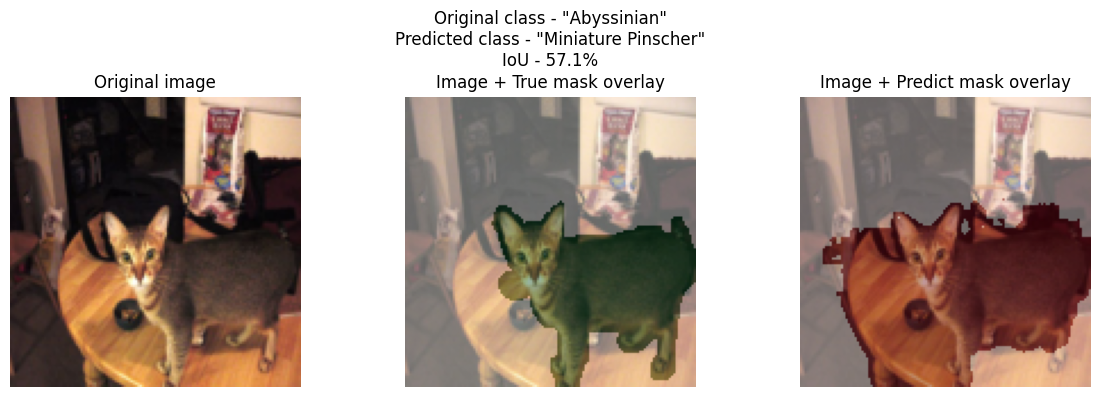

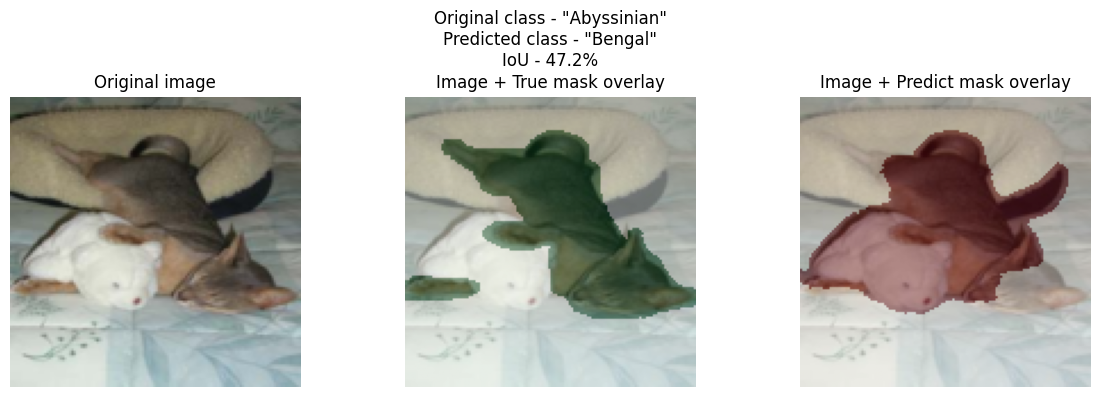

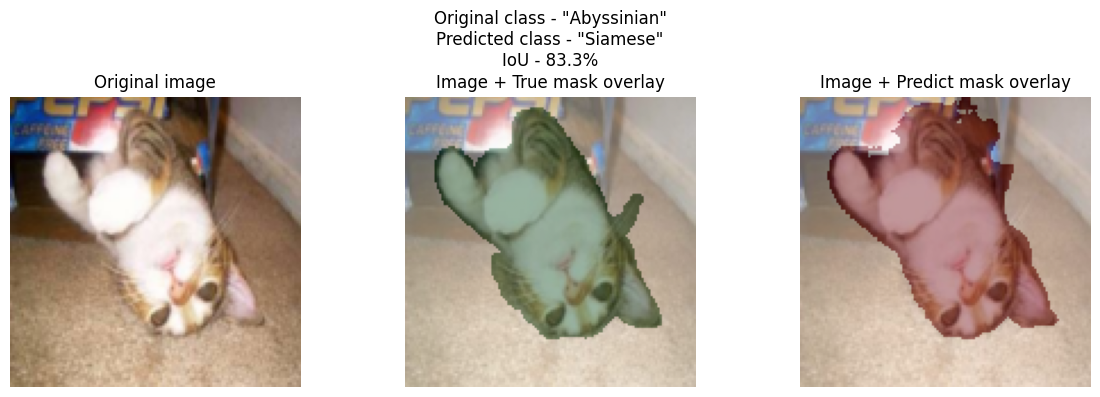

In [37]:
#Running inference on sample test images
for i in [0, 5, 10]:
    show_inference(i, x_test, x_test_norm, y_test, y_mask_test, class_names, model_dict)

In [38]:
#Augmentation for training images and masks
from skimage import transform as sktransform

def augment_pair(img, mask):
    if np.random.rand() > 0.5:
        img = np.fliplr(img).copy()
        mask = np.fliplr(mask).copy()
    if np.random.rand() > 0.5:
        angle = np.random.uniform(-20, 20)
        img = sktransform.rotate(img, angle, mode='reflect')
        mask = sktransform.rotate(mask, angle, order=0, mode='constant', cval=0, preserve_range=True)
    if np.random.rand() > 0.5:
        factor = np.random.uniform(0.7, 1.3)
        img = np.clip(img * factor, 0, 1)
    if np.random.rand() > 0.5:
        h, w = img.shape[:2]
        crop = np.random.uniform(0.8, 1.0)
        ch, cw = int(h*crop), int(w*crop)
        top = np.random.randint(0, h - ch + 1)
        left = np.random.randint(0, w - cw + 1)
        img = sktransform.resize(img[top:top+ch, left:left+cw], (h, w, 3), anti_aliasing=True)
        mask = sktransform.resize(mask[top:top+ch, left:left+cw], (h, w), order=0, preserve_range=True, anti_aliasing=False)
    mask = (mask > 0.5).astype(np.float32)
    return img, mask

In [39]:
#Batch loader with optional augmentation
class AugmentedBatchLoader():
    def __init__(self, x_raw, y_label, y_mask, mean, std, shuffle=True, batch_size=16, device='cpu', augment=False):
        self.x_raw, self.y_label_arr, self.y_mask_raw = x_raw, y_label, y_mask
        self.mean, self.std = mean, std
        self.shuffle, self.batch_size, self.device, self.augment = shuffle, batch_size, device, augment
        self.n = len(x_raw)
        self.len = (self.n + batch_size - 1) // batch_size
        self.iter = 0
        self.order = np.arange(self.n)
        if self.shuffle:
            np.random.shuffle(self.order)

    def next(self, task='both'):
        start = self.iter * self.batch_size
        end = min(start + self.batch_size, self.n)
        batch_idx = self.order[start:end]
        self.iter += 1
        if self.iter >= self.len:
            self.iter = 0
            if self.shuffle:
                np.random.shuffle(self.order)

        imgs, masks = [], []
        for i in batch_idx:
            img, mask = self.x_raw[i], self.y_mask_raw[i]
            if self.augment:
                img, mask = augment_pair(img, mask)
            imgs.append(img); masks.append(mask)
        imgs, masks = np.stack(imgs), np.stack(masks)
        imgs_norm = (imgs - self.mean) / (self.std + 1e-4)

        x_batch = torch.tensor(imgs_norm, dtype=torch.float32).permute(0,3,1,2).to(self.device)
        y_mask_batch = torch.tensor(masks, dtype=torch.float32).to(self.device)
        y_label_batch = torch.tensor(self.y_label_arr[batch_idx], dtype=torch.long).to(self.device)

        if task == 'classification': return x_batch, y_label_batch
        elif task == 'segmentation': return x_batch, y_mask_batch
        else: return x_batch, y_label_batch, y_mask_batch

In [40]:
#Instantiating v3 loaders (augmentation on for training only)
train_loader_v3 = AugmentedBatchLoader(x_train.astype(np.float32)/255.0, y_train, y_mask_train, mean, std, batch_size=16, device=device, augment=True)
train_loader_v3_eval = AugmentedBatchLoader(x_train.astype(np.float32)/255.0, y_train, y_mask_train, mean, std, shuffle=False, batch_size=16, device=device, augment=False)
val_loader_v3 = AugmentedBatchLoader(x_val.astype(np.float32)/255.0, y_val, y_mask_val, mean, std, shuffle=False, batch_size=16, device=device, augment=False)
test_loader_v3 = AugmentedBatchLoader(x_test.astype(np.float32)/255.0, y_test, y_mask_test, mean, std, shuffle=False, batch_size=16, device=device, augment=False)

In [41]:
#Regularized classifier head with dropout
class RegularizedClassifier(nn.Module):
    def __init__(self, in_channels, num_classes, dropout_p=0.5):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, in_channels, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(in_channels)
        self.drop1 = nn.Dropout2d(dropout_p)
        self.conv2 = nn.Conv2d(in_channels, in_channels//2, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(in_channels//2)
        self.drop2 = nn.Dropout(dropout_p)
        self.conv3 = nn.Conv2d(in_channels//2, num_classes, kernel_size=1)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.drop1(x)
        x = F.relu(self.bn2(self.conv2(x)))
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        x = self.drop2(x)
        return self.conv3(x.unsqueeze(-1).unsqueeze(-1)).squeeze(-1).squeeze(-1)

In [42]:
#Instantiating Base U-Net v3 (regularized, augmented)
from sklearn.utils.class_weight import compute_class_weight

LR = 1e-4
WEIGHT_DECAY = 1e-3
NUM_EPOCHS = 30

encoder_v3 = UNetEncoder(in_channels=3, base_channels=32).to(device)
bottleneck_v3 = UNetBottleneck(256).to(device)
decoder_v3 = UNetDecoder(512).to(device)
classifier_v3 = RegularizedClassifier(512, num_classes).to(device)
model_dict_v3 = {'encoder': encoder_v3, 'bottleneck': bottleneck_v3, 'decoder': decoder_v3, 'classifier': classifier_v3}

optimizer_v3 = torch.optim.AdamW(
    list(encoder_v3.parameters()) + list(bottleneck_v3.parameters()) +
    list(decoder_v3.parameters()) + list(classifier_v3.parameters()),
    lr=LR, weight_decay=WEIGHT_DECAY
)
scheduler_v3 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_v3, T_max=NUM_EPOCHS)

class_weights = compute_class_weight('balanced', classes=np.arange(num_classes), y=y_train)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
classifier_loss_fn = nn.CrossEntropyLoss(weight=class_weights_tensor, label_smoothing=0.1)

In [43]:
#Timing one v3 epoch
import time
start = time.time()
run_epoch(train_loader_v3, model_dict_v3, optimizer_v3, train=True)
print(time.time() - start)

34.99877715110779


In [44]:
#Training Base U-Net v3 (augmented + regularized)
CHECKPOINT_NAME = "base_unet_v3"
NUM_EPOCHS = 30
SAVE_EVERY = 5
PATIENCE = 5

start_epoch, best_metric = load_checkpoint(model_dict_v3, optimizer_v3, CHECKPOINT_NAME, scheduler=scheduler_v3)
best_metric = best_metric if best_metric is not None else 0
epochs_without_improvement = 0

for epoch in range(start_epoch, NUM_EPOCHS):
    train_loss, train_iou, train_dice, train_acc, train_cls_acc = run_epoch(train_loader_v3, model_dict_v3, optimizer_v3, train=True)
    val_loss, val_iou, val_dice, val_acc, val_cls_acc = run_epoch(val_loader_v3, model_dict_v3, optimizer_v3, train=False)
    scheduler_v3.step()

    print(epoch, train_loss, train_iou, train_cls_acc, val_loss, val_iou, val_cls_acc)

    if val_cls_acc > best_metric:
        best_metric = val_cls_acc
        epochs_without_improvement = 0
        save_checkpoint(model_dict_v3, optimizer_v3, epoch+1, best_metric, CHECKPOINT_NAME + "_best", scheduler=scheduler_v3)
    else:
        epochs_without_improvement += 1

    if (epoch+1) % SAVE_EVERY == 0 or (epoch+1) == NUM_EPOCHS:
        save_checkpoint(model_dict_v3, optimizer_v3, epoch+1, best_metric, CHECKPOINT_NAME, scheduler=scheduler_v3)

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}: no improvement for {PATIENCE} epochs")
        break

0 2.0282853379541512 0.6631772901330676 0.09598214285714286 1.9527806520462037 0.69642322574343 0.11964285714285715
1 1.9247915562318296 0.6916433323402794 0.13010204081632654 1.9391744988305228 0.6930547509874616 0.10535714285714286
2 1.8593106811143914 0.7130861130295968 0.1527423469387755 1.813259608404977 0.7371805957385472 0.15714285714285714
3 1.782594186919076 0.7353171307821663 0.18080357142857142 1.8000838790621077 0.7373620203563145 0.14464285714285716
4 1.735247396084727 0.7455834274997517 0.19387755102040816 1.9484651259013586 0.7591301492282323 0.09285714285714286
5 1.6807212519402406 0.7590198586789929 0.22863520408163265 1.6834716320037841 0.7725151027951922 0.2017857142857143
6 1.6195941074770324 0.7699918190435487 0.2385204081632653 1.5904456785746983 0.7775742360523769 0.24107142857142858
7 1.5787153511631244 0.7727011880096124 0.2659438775510204 1.5488544872828893 0.7688269308635167 0.2732142857142857
8 1.5199542009100622 0.7797881668927719 0.3086734693877551 1.46810

In [46]:
#Reporting Base U-Net v3 metrics across all splits
import pandas as pd

load_checkpoint(model_dict_v3, optimizer_v3, "base_unet_v3_best", scheduler=scheduler_v3)
results_v3 = {}
for name, loader in [('train', train_loader_v3_eval), ('val', val_loader_v3), ('test', test_loader_v3)]:
    results_v3[name] = evaluate(loader, model_dict_v3)
metrics_df_v3 = pd.DataFrame(results_v3).T.round(4)
metrics_df_v3

,mIoU,dice,pixel_acc,cls_acc,precision,recall,f1
train,0.8642,0.9233,0.9441,0.8355,0.8427,0.8351,0.8262
val,0.8325,0.9013,0.9290,0.5911,0.5981,0.5900,0.5792
test,0.8343,0.9029,0.9282,0.5420,0.5454,0.5418,0.5336


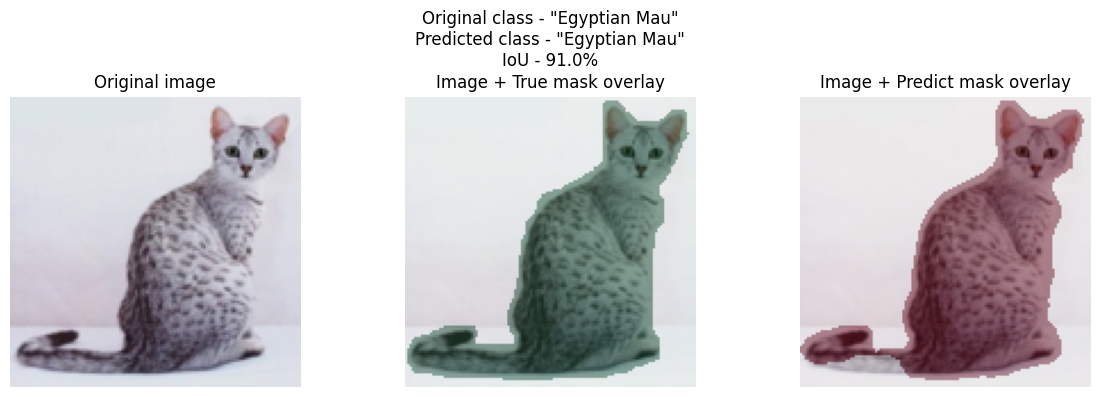

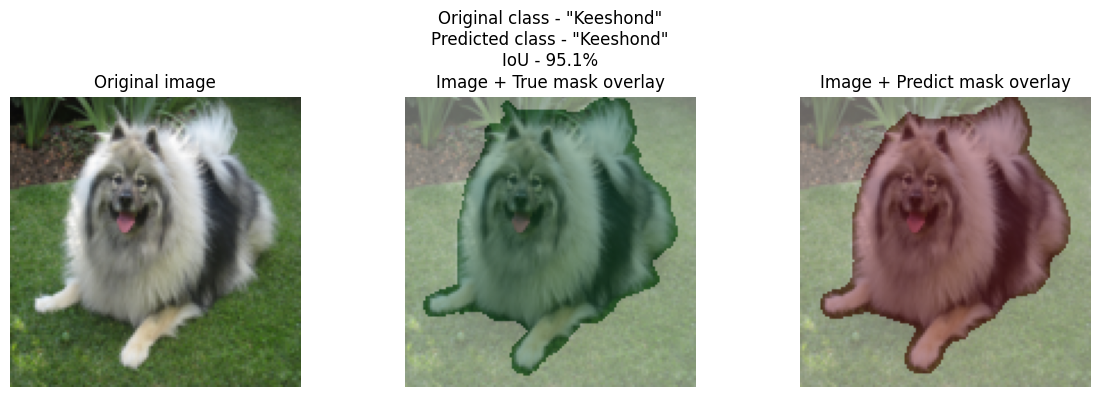

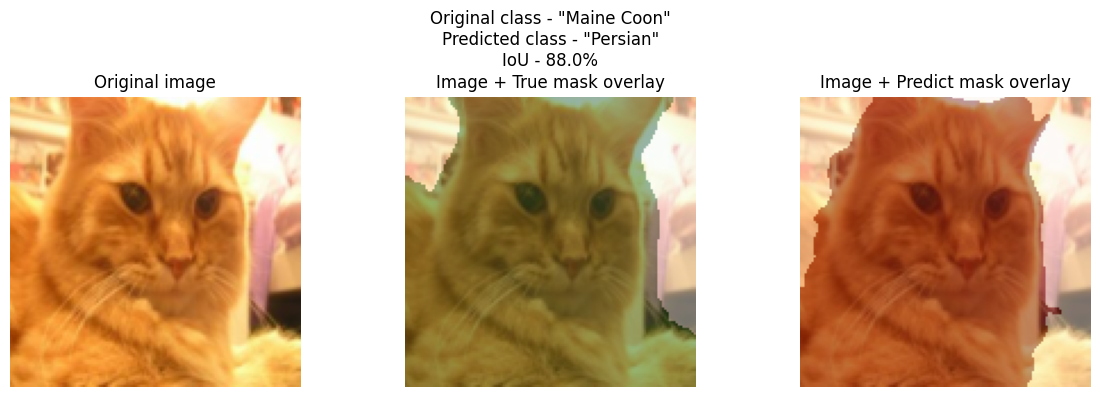

In [48]:
#Running inference on sample test images - Base U-Net v3
import random

for i in random.sample(range(len(x_test)), 3):
    show_inference(i, x_test, (x_test.astype(np.float32)/255.0 - mean)/(std+1e-4), y_test, y_mask_test, class_names, model_dict_v3)

## 3. Attention U-Net + Classifier

In [49]:
#Attention gate
class AttentionGate(nn.Module):
    def __init__(self, gate_channels, skip_channels, inter_channels):
        super().__init__()
        self.W_gate = nn.Sequential(nn.Conv2d(gate_channels, inter_channels, 1), nn.BatchNorm2d(inter_channels))
        self.W_skip = nn.Sequential(nn.Conv2d(skip_channels, inter_channels, 1), nn.BatchNorm2d(inter_channels))
        self.psi = nn.Sequential(nn.Conv2d(inter_channels, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())

    def forward(self, gate, skip):
        combined = F.relu(self.W_gate(gate) + self.W_skip(skip))
        attention = self.psi(combined)
        return skip * attention

In [50]:
#Attention decoder block
class AttentionDecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.attn = AttentionGate(gate_channels=out_channels, skip_channels=out_channels, inter_channels=out_channels//2)
        self.conv = ConvBlock(out_channels*2, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        skip_attended = self.attn(x, skip)
        return self.conv(torch.cat([skip_attended, x], dim=1))

In [51]:
#Attention U-Net decoder
class AttentionUNetDecoder(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.dec4 = AttentionDecoderBlock(in_channels, in_channels//2)
        self.dec3 = AttentionDecoderBlock(in_channels//2, in_channels//4)
        self.dec2 = AttentionDecoderBlock(in_channels//4, in_channels//8)
        self.dec1 = AttentionDecoderBlock(in_channels//8, in_channels//16)
        self.final_conv = nn.Conv2d(in_channels//16, 1, kernel_size=1)

    def forward(self, x5, x4, x3, x2, x1):
        x = self.dec4(x5, x4)
        x = self.dec3(x, x3)
        x = self.dec2(x, x2)
        x = self.dec1(x, x1)
        return self.final_conv(x).squeeze(1)

In [52]:
#Instantiating attention models and optimizer
encoder_attn = UNetEncoder(in_channels=3, base_channels=32).to(device)
bottleneck_attn = UNetBottleneck(256).to(device)
decoder_attn = AttentionUNetDecoder(512).to(device)
classifier_attn = Classifier(512, num_classes).to(device)

model_dict_attn = {'encoder': encoder_attn, 'bottleneck': bottleneck_attn, 'decoder': decoder_attn, 'classifier': classifier_attn}

optimizer_attn = torch.optim.AdamW(
    list(encoder_attn.parameters()) + list(bottleneck_attn.parameters()) +
    list(decoder_attn.parameters()) + list(classifier_attn.parameters()),
    lr=1e-3
)

In [53]:
#Training Attention U-Net
CHECKPOINT_NAME_ATTN = "attention_unet"
NUM_EPOCHS = 25
SAVE_EVERY = 5

start_epoch, best_metric = load_checkpoint(model_dict_attn, optimizer_attn, CHECKPOINT_NAME_ATTN)
best_metric = best_metric if best_metric is not None else 0

for epoch in range(start_epoch, NUM_EPOCHS):
    train_loss, train_iou, train_dice, train_acc, train_cls_acc = run_epoch(train_loader, model_dict_attn, optimizer_attn, train=True)
    val_loss, val_iou, val_dice, val_acc, val_cls_acc = run_epoch(val_loader, model_dict_attn, optimizer_attn, train=False)

    print(epoch, train_loss, train_iou, train_cls_acc, val_loss, val_iou, val_cls_acc)

    if val_iou > best_metric:
        best_metric = val_iou
        save_checkpoint(model_dict_attn, optimizer_attn, epoch+1, best_metric, CHECKPOINT_NAME_ATTN + "_best")

    if (epoch+1) % SAVE_EVERY == 0 or (epoch+1) == NUM_EPOCHS:
        save_checkpoint(model_dict_attn, optimizer_attn, epoch+1, best_metric, CHECKPOINT_NAME_ATTN)

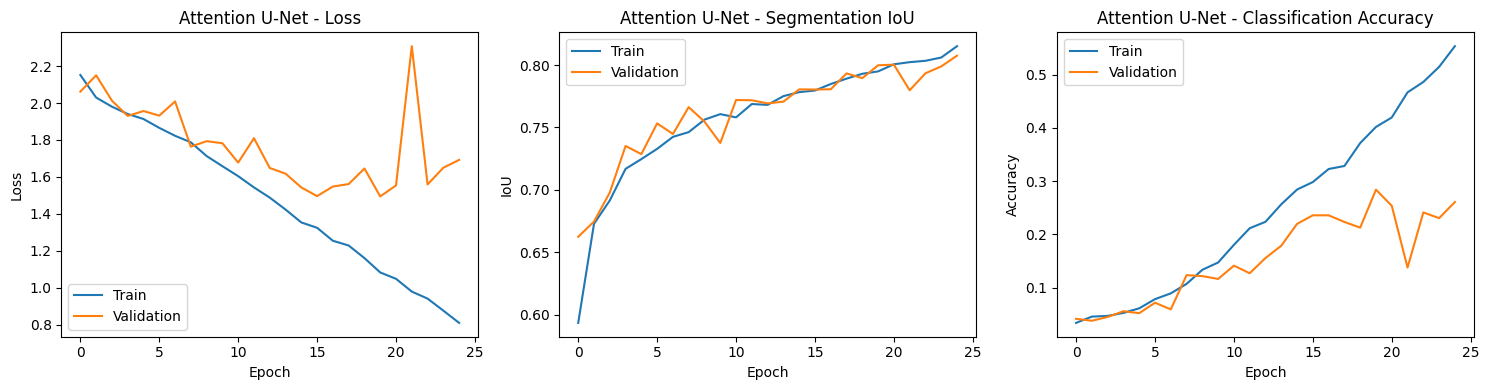

In [54]:
#Training history - Attention U-Net
attention_unet_history = {
    'epoch': list(range(25)),
    'train_loss': [2.1517,2.0296,1.9802,1.9405,1.9133,1.8654,1.8225,1.7872,1.7128,1.6579,1.6039,1.5429,1.4877,1.4231,1.3532,1.3243,1.2541,1.2283,1.1601,1.0824,1.0480,0.9788,0.9408,0.8755,0.8093],
    'train_iou':  [0.5936,0.6729,0.6916,0.7169,0.7247,0.7329,0.7425,0.7463,0.7563,0.7607,0.7581,0.7688,0.7681,0.7751,0.7783,0.7796,0.7848,0.7891,0.7930,0.7949,0.8006,0.8023,0.8034,0.8060,0.8151],
    'train_cls_acc': [0.0335,0.0453,0.0466,0.0523,0.0609,0.0781,0.0890,0.1068,0.1333,0.1470,0.1802,0.2114,0.2235,0.2564,0.2841,0.2982,0.3227,0.3284,0.3715,0.4018,0.4196,0.4668,0.4863,0.5147,0.5536],
    'val_loss': [2.0617,2.1499,2.0128,1.9300,1.9565,1.9317,2.0086,1.7636,1.7933,1.7822,1.6774,1.8095,1.6481,1.6175,1.5428,1.4958,1.5477,1.5610,1.6453,1.4941,1.5535,2.3078,1.5590,1.6496,1.6921],
    'val_iou':  [0.6625,0.6747,0.6979,0.7352,0.7287,0.7533,0.7448,0.7663,0.7547,0.7376,0.7720,0.7718,0.7693,0.7707,0.7805,0.7804,0.7806,0.7933,0.7895,0.7998,0.8003,0.7798,0.7934,0.7989,0.8075],
    'val_cls_acc': [0.0411,0.0375,0.0446,0.0554,0.0518,0.0714,0.0589,0.1232,0.1214,0.1161,0.1411,0.1268,0.1554,0.1786,0.2196,0.2357,0.2357,0.2232,0.2125,0.2839,0.2536,0.1375,0.2411,0.2304,0.2607],
}

plot_history(attention_unet_history, 'Attention U-Net')

In [55]:
#Loading best attention checkpoint for evaluation
load_checkpoint(model_dict_attn, optimizer_attn, CHECKPOINT_NAME_ATTN + "_best")

(25, 0.8074862224715097)

In [56]:
#Reporting attention metrics across all splits
for name, loader in [('train', train_loader), ('val', val_loader), ('test', test_loader)]:
    r = evaluate(loader, model_dict_attn)
    print(name, r['mIoU'], r['dice'], r['pixel_acc'], r['cls_acc'], r['precision'], r['recall'], r['f1'])

train 0.8262538943363695 0.8989409339063021 0.9236147744315011 0.5373086734693877 0.5956511958250756 0.5385953551707522 0.5205963183795522
val 0.8074862224715097 0.8851896592548916 0.9119875226702009 0.26071428571428573 0.2571060691312564 0.2606177606177606 0.2400816865147397
test 0.8068095277185026 0.8851152347481769 0.9117536759894828 0.24788043479556623 0.2714605038965742 0.24838551007222712 0.23405652388653678


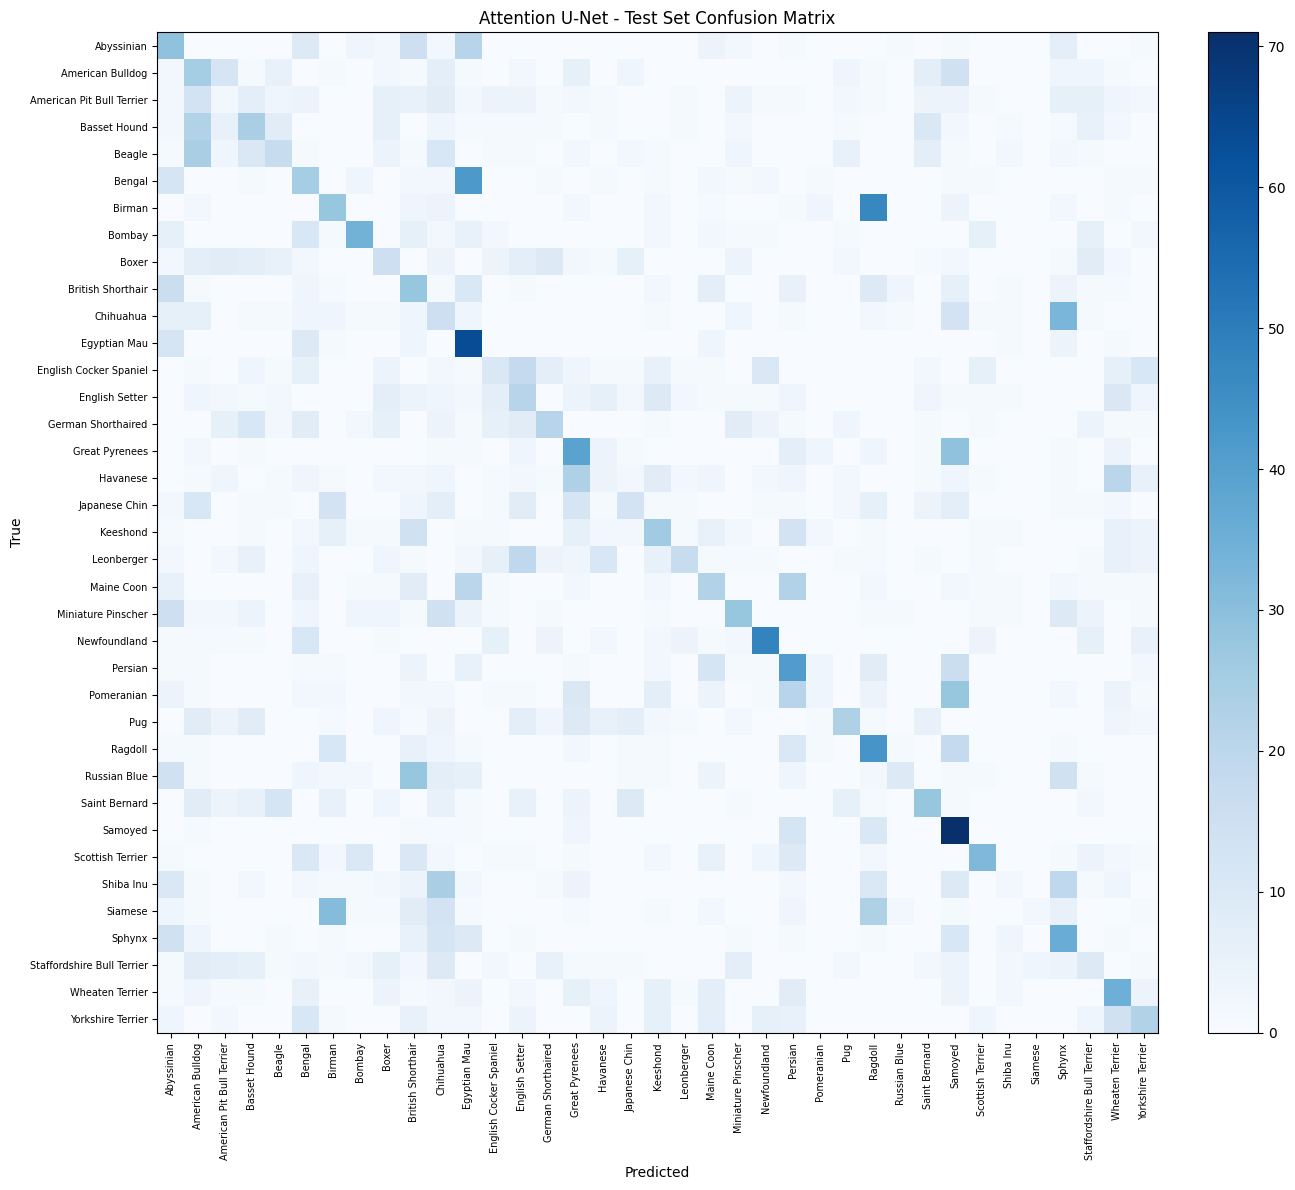

In [57]:
#Confusion matrix - Attention U-Net
preds_attn, labels_attn = get_predictions(test_loader, model_dict_attn)
plot_confusion_matrix(preds_attn, labels_attn, class_names, 'Attention U-Net - Test Set Confusion Matrix')

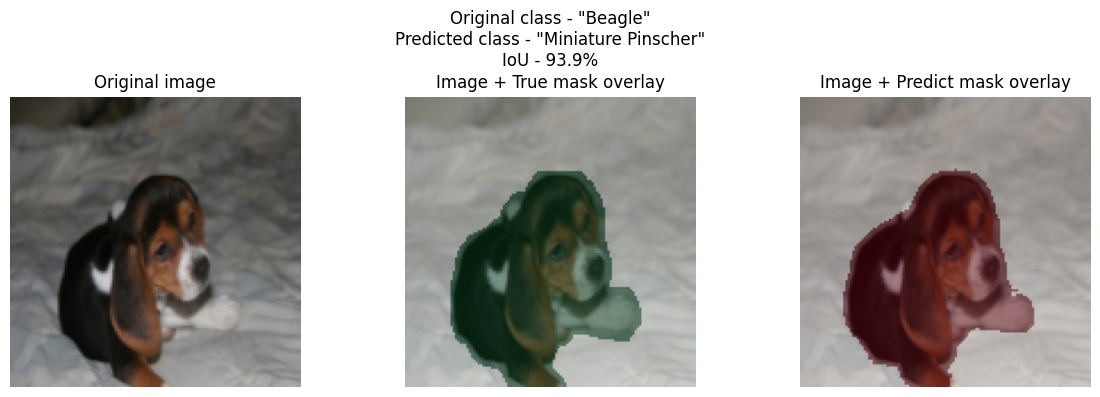

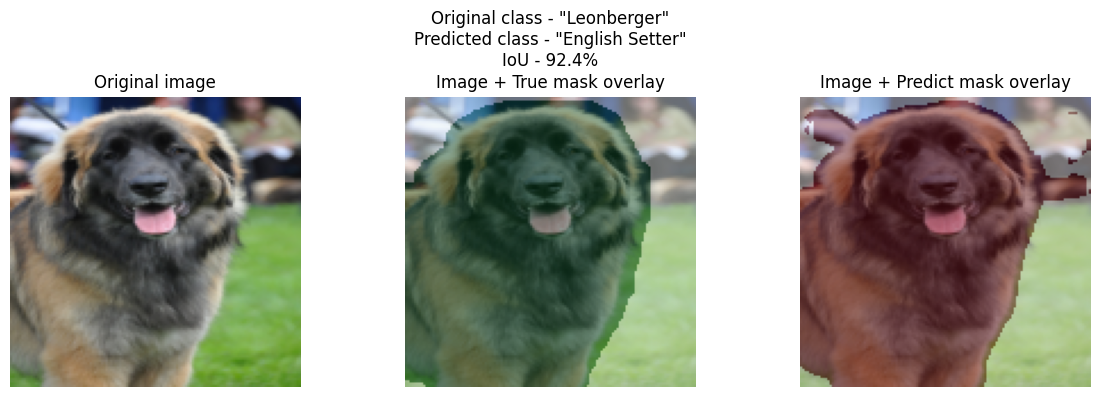

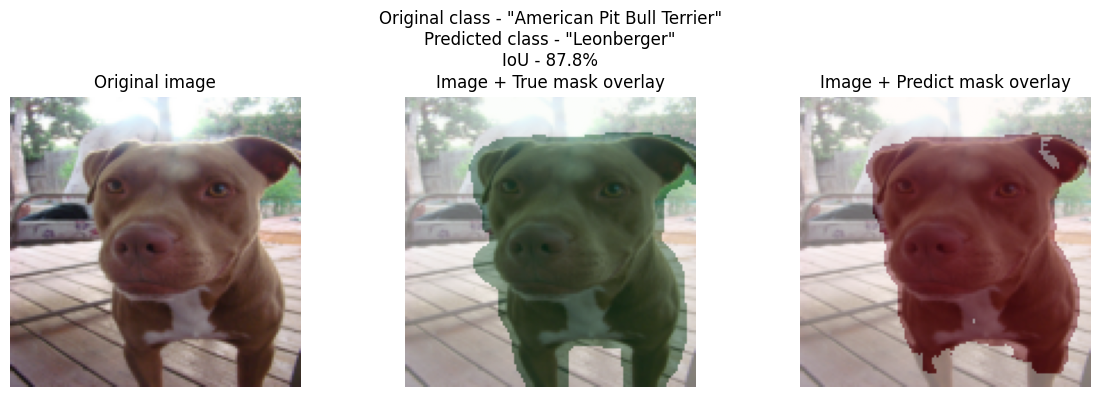

In [58]:
#Running attention inference on random test images
import random
random_idx = random.sample(range(len(x_test)), 3)
for i in random_idx:
    show_inference(i, x_test, x_test_norm, y_test, y_mask_test, class_names, model_dict_attn)

In [61]:
#Clearing mismatched Attention U-Net v3 checkpoint
for f in ["attention_unet_v3.pt", "attention_unet_v3_best.pt"]:
    path = f"{CHECKPOINT_DIR}/{f}"
    if os.path.exists(path):
        os.remove(path)
        print("removed", f)

removed attention_unet_v3.pt
removed attention_unet_v3_best.pt


In [62]:
#Instantiating Attention U-Net v3 (regularized, augmented)
NUM_EPOCHS = 30

encoder_attn_v3 = UNetEncoder(in_channels=3, base_channels=32).to(device)
bottleneck_attn_v3 = UNetBottleneck(256).to(device)
decoder_attn_v3 = AttentionUNetDecoder(512).to(device)
classifier_attn_v3 = RegularizedClassifier(512, num_classes).to(device)
model_dict_attn_v3 = {'encoder': encoder_attn_v3, 'bottleneck': bottleneck_attn_v3, 'decoder': decoder_attn_v3, 'classifier': classifier_attn_v3}

optimizer_attn_v3 = torch.optim.AdamW(
    list(encoder_attn_v3.parameters()) + list(bottleneck_attn_v3.parameters()) +
    list(decoder_attn_v3.parameters()) + list(classifier_attn_v3.parameters()),
    lr=LR, weight_decay=WEIGHT_DECAY
)
scheduler_attn_v3 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_attn_v3, T_max=NUM_EPOCHS)

In [63]:
#Training Attention U-Net v3 (augmented + regularized)
CHECKPOINT_NAME_ATTN = "attention_unet_v3"
epochs_without_improvement = 0
start_epoch, best_metric = load_checkpoint(model_dict_attn_v3, optimizer_attn_v3, CHECKPOINT_NAME_ATTN, scheduler=scheduler_attn_v3)
best_metric = best_metric if best_metric is not None else 0

for epoch in range(start_epoch, NUM_EPOCHS):
    train_loss, train_iou, train_dice, train_acc, train_cls_acc = run_epoch(train_loader_v3, model_dict_attn_v3, optimizer_attn_v3, train=True)
    val_loss, val_iou, val_dice, val_acc, val_cls_acc = run_epoch(val_loader_v3, model_dict_attn_v3, optimizer_attn_v3, train=False)
    scheduler_attn_v3.step()

    print(epoch, train_loss, train_iou, train_cls_acc, val_loss, val_iou, val_cls_acc)

    if val_cls_acc > best_metric:
        best_metric = val_cls_acc
        epochs_without_improvement = 0
        save_checkpoint(model_dict_attn_v3, optimizer_attn_v3, epoch+1, best_metric, CHECKPOINT_NAME_ATTN + "_best", scheduler=scheduler_attn_v3)
    else:
        epochs_without_improvement += 1

    if (epoch+1) % 5 == 0 or (epoch+1) == NUM_EPOCHS:
        save_checkpoint(model_dict_attn_v3, optimizer_attn_v3, epoch+1, best_metric, CHECKPOINT_NAME_ATTN, scheduler=scheduler_attn_v3)

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}: no improvement for {PATIENCE} epochs")
        break

0 2.1813356274244735 0.6035021908429204 0.055165816326530615 2.0741374628884452 0.6526430981499808 0.06607142857142857
1 2.031075936190936 0.6685116595151473 0.10204081632653061 1.9674429689134871 0.6707612344196865 0.10357142857142858
2 1.9429718833796832 0.6991836617187578 0.12053571428571429 1.8748090165002005 0.7160930548395429 0.1357142857142857
3 1.8612513256316283 0.7197038263690715 0.1591198979591837 1.846125374521528 0.7168579067502703 0.15
4 1.8008682557514735 0.7362339003961913 0.1725127551020408 1.7653039693832397 0.7497058647019522 0.17142857142857143
5 1.733506525657615 0.7507663600298823 0.19387755102040816 1.7422894784382412 0.7688911710466657 0.15
6 1.6764298689608672 0.7637446452768482 0.2152423469387755 1.6168789897646223 0.7737780570983886 0.22142857142857142
7 1.6215176716142772 0.7701205015182495 0.24170918367346939 1.5712963240487234 0.7817499995231628 0.25357142857142856
8 1.5801677782924808 0.7785778954929236 0.27040816326530615 1.5575521911893573 0.77999048914

In [64]:
#Reporting Attention U-Net v3 metrics across all splits
import pandas as pd

load_checkpoint(model_dict_attn_v3, optimizer_attn_v3, "attention_unet_v3_best", scheduler=scheduler_attn_v3)
results_attn_v3 = {}
for name, loader in [('train', train_loader_v3_eval), ('val', val_loader_v3), ('test', test_loader_v3)]:
    results_attn_v3[name] = evaluate(loader, model_dict_attn_v3)
metrics_df_attn_v3 = pd.DataFrame(results_attn_v3).T.round(4)
metrics_df_attn_v3

,mIoU,dice,pixel_acc,cls_acc,precision,recall,f1
train,0.8638,0.9230,0.9441,0.8064,0.8125,0.8058,0.7947
val,0.8316,0.9004,0.9289,0.5607,0.5663,0.5607,0.5462
test,0.8324,0.9013,0.9270,0.5235,0.5116,0.5234,0.5108


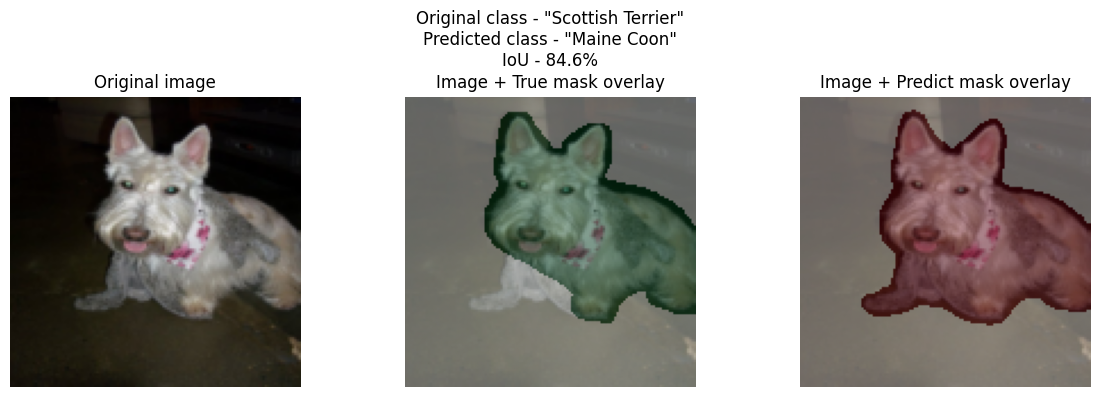

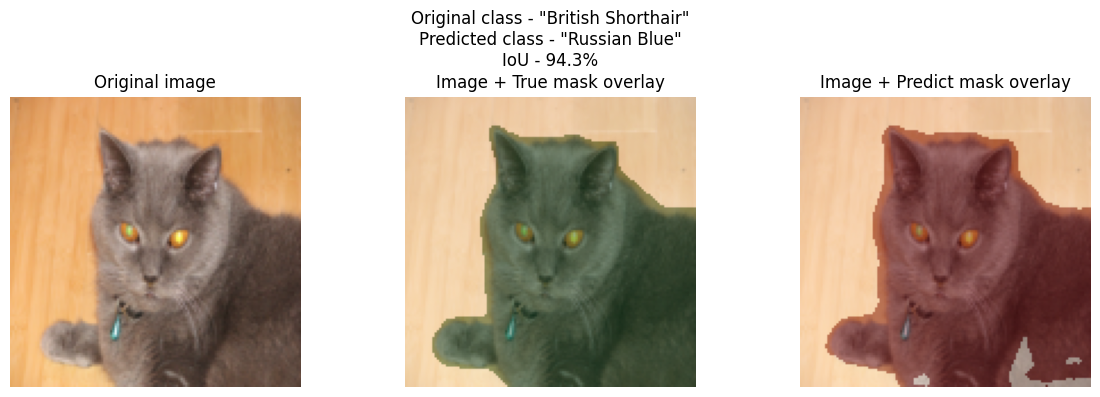

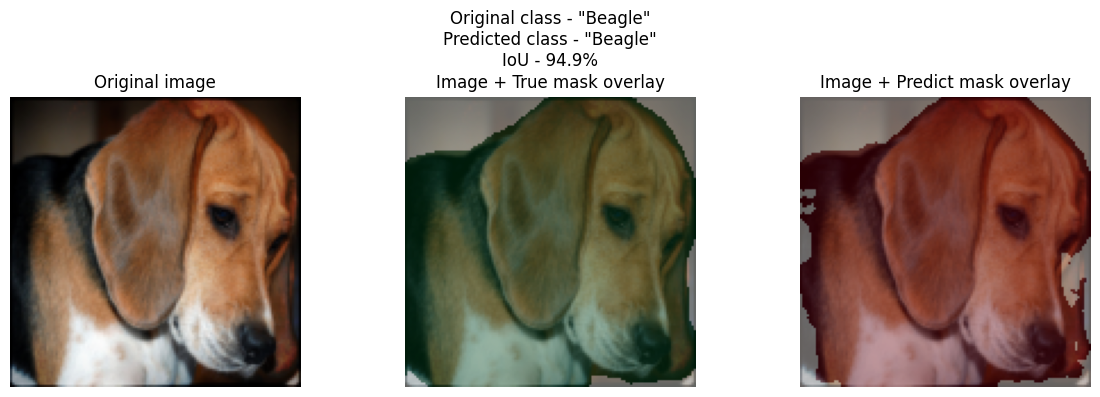

In [65]:
#Running inference on sample test images - Attention U-Net v3
for i in random.sample(range(len(x_test)), 3):
    show_inference(i, x_test, (x_test.astype(np.float32)/255.0 - mean)/(std+1e-4), y_test, y_mask_test, class_names, model_dict_attn_v3)

## 4. Bonus Tasks

## 5. Inference Demo

## 6. Results Summary